# Regresión Lineal Simple

## ¿Cuál es el objetivo de una regresión lineal?

El objetivo de una regresión lineal simple es encontrar una **relación lineal** entre una variable independiente $x$ (también llamada **predictora** o **explicativa**) y una variable dependiente $y$ (también llamada **respuesta** u **objetivo**).

Buscamos encontrar una función de la forma:

$$
\hat{y} = b_0 + b_1 x
$$

Donde:

- $\hat{y}$: valor a predecir de la variable dependiente.
- $b_0$: intercepto (el valor de $y$ cuando $x = 0$).
- $b_1$: pendiente (cuánto cambia $y$, cuando $x$ aumenta una unidad. Es la pendiente de la recta).

Al final una regresión lineal, es encontrar una ecuación de una linea recta que pueda ser útil para predecir valores.

**Supongamos un conjunto de datos simples**

Tomemos estos puntos que parecen estar relacionados linealmente:

| \(x\) | \(y\) |
|------|------|
| 0    | 1    |
| 1    | 2    |
| 2    | 4    |
| 3    | 6    |
| 4    | 8    |

Visualmente, estos puntos no están perfectamente alineados, pero parece que una línea recta podría aproximarlos bastante bien.

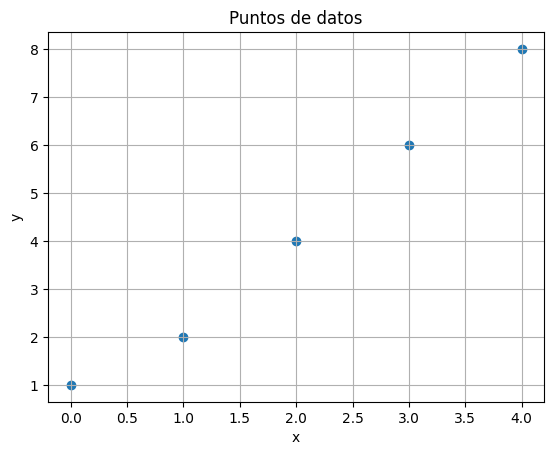

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.array([0, 1, 2, 3, 4])
y = np.array([1, 2, 4, 6, 8])

plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Puntos de datos')
plt.grid(True)
plt.show()

## ¿Qué línea es la "mejor"?


Al ver los datos anteriores, puede surgir una pregunta, ¿**cual es la mejor línea recta que puede representar mejor los datos?** Pero... **¿qué significa mejor?**

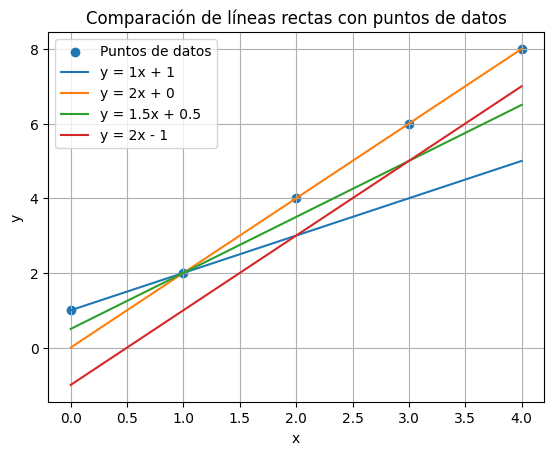

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Datos
x = np.array([0, 1, 2, 3, 4])
y = np.array([1, 2, 4, 6, 8])

x_line = np.linspace(0, 4, 100)

# Líneas rectas con diferentes parámetros
lines = [
    (1, 1, 'y = 1x + 1'),
    (2, 0, 'y = 2x + 0'),
    (1.5, 0.5, 'y = 1.5x + 0.5'),
    (2, -1, 'y = 2x - 1'),
]

# Graficar puntos
plt.scatter(x, y, label='Puntos de datos')

# Graficar líneas
for m, b, label in lines:
    y_line = m * x_line + b
    plt.plot(x_line, y_line, label=label)

plt.xlabel('x')
plt.ylabel('y')
plt.title('Comparación de líneas rectas con puntos de datos')
plt.grid(True)
plt.legend()
plt.show()

Una forma de saber cual recta es mejor es pensar lo siguiente: queremos que la ecuación de la línea recta pase por todos los puntos que tengo o en su defecto, que pasen lo mas cerca posible de casa uno de ellos. Es decir, buscamos que la línea recta pase lo mas cerca posible por todos los puntos de mis datos.

Ahora bien, por un momento pensemos también lo siguiente, **¿como podemos medir que tan cerca o que tan lejos está los puntos de datos de la línea recta?**

La respuesta está en calcular la diferencia entre el valor real de los datos y el valor predicho por la recta para cada punto. Esta diferencia se conoce como **error** o **residuo**.


Matemáticamente, si tenemos un punto $(x_i, y_i)$, y la recta predice un valor $ \hat{y}_i = mx_i + b $, entonces el error es:

$$
e_i = y_i - \hat{y}_i
$$

Como nuestro objetivo es medir qué tan lejos están todos los puntos de la recta, podríamos pensar en sumar todos los errores. Sin embargo, esto no funcionaría bien, ya que, algunos errores serán positivos y otros negativos, y podrían cancelarse entre sí.

Para evitar esto, podemos elevar los errores al cuadrado. Esto hace que todos los errores se vuelvan positivos y penaliza más los errores grandes. Luego, podemos sumar ahora sí todos estos errores al cuadrado.

$$
\text{Suma de errores cuadráticos} = \sum_{i=1}^n (y_i - \hat{y}_i)^2 = \sum_{i=1}^{n} (y_i - b_0 - b_1 x_i)^2
$$

El objetivo de la **regresión lineal** es encontrar los valores de la pendiente ($m$) y del intercepto ($b$) que **minimicen** esta suma. A este método se le conoce como el **método de mínimos cuadrados** o OLS, por sus siglas en inglés.

## Demostración Matemática

### Paso 1: Función de costo

Para encontrar la mejor recta posible para nuestros datos, debemos minimar la suma de los errores cuadrados. Esto se hace definiendo algo que se llama función de costo o función objetivo.

$$
J(b_0, b_1) = \sum_{i=1}^{n} (y_i - b_0 - b_1 x_i)^2
$$

Nuestro objetivo es encontrar los valores de ($b_0$) y ($b_1$) que **minimicen** esta función ($J$).

Para esto, nos vamos apoyar del **cálculo diferencial**, específicamente usando derivadas parciales. La idea es encontrar los puntos críticos de la función de costo, es decir, los valores de $b_0$ y $b_1$ donde la derivada es cero.

### Paso 2: Derivadas parciales

Derivamos la función de costo con respecto a cada parámetro con la regla de la cadena:

*   Derivada parcial con respecto a ($b_0$):
$$
\frac{\partial J}{\partial b_0} = -2 \sum_{i=1}^{n} (y_i - b_0 - b_1 x_i)
$$

*   Derivada parcial con respecto a ($b_1$):
$$
\frac{\partial J}{\partial b_1} = -2 \sum_{i=1}^{n} x_i (y_i - b_0 - b_1 x_i)
$$

Luego, igualamos ambas derivadas a cero para encontrar los valores que minimizan la función:

$$
\frac{\partial J}{\partial b_0} = -2 \sum_{i=1}^{n} (y_i - b_0 - b_1 x_i) = 0\tag{1}
$$

$$\frac{\partial J}{\partial b_1} = -2 \sum_{i=1}^{n} x_i (y_i - b_0 - b_1 x_i) = 0\tag{2}
$$

Esto nos lleva a un sistema de ecuaciones que podemos resolver para obtener los valores de $b_0$ y $b_1$ que minimicen la suma del error cuadratico.

### Paso 3: Resolver el sistema de ecuaciones

Lo primero que debemos realizar, para resolver el sistema de ecuaciones (1) y (2), es distribuir la sumatoria y dividir en ambos lados por $-2$.

*   De (1):
$$
\sum_{i=1}^{n}y_i - \sum_{i=1}^{n}b_0 - \sum_{i=1}^{n} b_1x_i = 0
$$
*  De (2):
$$
\sum_{i=1}^{n} x_i y_i - \sum_{i=1}^{n} b_0 x_i - \sum_{i=1}^{n} b_1x_i^2 = 0
$$

Para simplificar estos términos, podemos aplicar la propiedade de la sumatoria de que la sumatoria de una constante es igual a $n$ veces esa constante, $\sum_{i=1}^{n} a = na$. Y además, podemos ver que terminos como $b_0$ o $b_1$ son independientes de la indice de la sumatoria, es decir, son constantes y puede salir de la sumatoria.

Obteniendo así:
$$
\sum_{i=1}^{n}y_i - nb_0 - b_1\sum_{i=1}^{n}x_i = 0 \tag{3}
$$
$$
\sum_{i=1}^{n} x_i y_i - b_0\sum_{i=1}^{n}x_i - b_1\sum_{i=1}^{n}x_i^2 = 0 \tag{4}
$$


En este punto, podemos notar que estas expresiones pueden volverse algo complicadas de manejar, especialmente si continuamos con tantas sumatorias. Una estrategia muy útil para simplificar este tipo de sistemas es introducir las **medias muestrales** de los datos.

¿Por qué hacer esto?, esto nos permiten expresar las sumatorias más largas de forma compacta. Por ejemplo, en lugar de trabajar con $\sum x_i$, podemos usar la relación $\sum x_i = n \bar{x}$, donde $\bar{x}$ es el promedio de los valores de $x$. Y también, dentro de la formulación y supuestos de la regresión línea (esto se omite en este ejemplo, pero es importante saberlo) porque existe una propiedad importante en la regresión lineal, la recta ajustada siempre pasa por el punto medio de los datos, es decir, por el punto $(\bar{x}, \bar{y})$. Esta propiedad se vuelve evidente al incorporar las medias en el sistema.

Recordemos las definiciones de las medias muestrales:

$$
\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i, \quad \bar{y} = \frac{1}{n} \sum_{i=1}^{n} y_i
$$

Por lo tanto:

$$
\sum_{i=1}^{n} x_i = n \bar{x}, \quad \sum_{i=1}^{n} y_i = n \bar{y}
$$

Sustituyendo estas relaciones en las ecuaciones (3) y (4), obtenemos un sistema mucho más sencillo, que además nos lleva naturalmente a deducir la relación entre los parámetros de la recta y las características estadísticas de los datos.

Sustituyendo esto en las ecuaciones (3) y (4), obtenemos:

- De (3):

$$
n \bar{y} - n b_0 - b_1 n \bar{x} = 0
\quad \Rightarrow \quad
\bar{y} = b_0 + b_1 \bar{x} \tag{5}
$$

Esta ecuación es importante, ya que relaciona las medias de los datos con los parámetros de la recta. Es una condición de equilibrio, la recta de la regresión siempre pasa por el punto medio $(\bar{x}, \bar{y})$.

- De (4):
$$
\sum_{i=1}^{n} x_i y_i - b_0\sum_{i=1}^{n} x_i - b_1 \sum_{i=1}^{n} x_i^2 = 0 \tag{6}
$$

Pero gracias a la ecuación (5), podemos reemplazar $b_0 = \bar{y} - b_1 \bar{x}$ en esta ecuación para obtener una expresión solo en función de $b_1$. El siguiente paso sería despejar $b_1$ usando este resultados.

Finalmente:
*   De (6):
$$
\sum_{i=1}^{n} x_i y_i - (\bar{y} - b_1 \bar{x}) \sum_{i=1}^{n} x_i - b_1 \sum_{i=1}^{n} x_i^2 = 0
$$

Distribuimos:

$$
\sum_{i=1}^{n} x_i y_i - \bar{y} \sum_{i=1}^{n} x_i + b_1 \bar{x} \sum_{i=1}^{n} x_i - b_1 \sum_{i=1}^{n} x_i^2 = 0
$$

Agrupamos los términos con $b_1$:

$$
\sum_{i=1}^{n} x_i y_i - \bar{y} \sum_{i=1}^{n} x_i + b_1 \left( \bar{x} \sum_{i=1}^{n} x_i - \sum_{i=1}^{n} x_i^2 \right) = 0
$$

Recordamos que:

$$
\sum_{i=1}^{n} x_i = n \bar{x}
\quad \Rightarrow \quad \bar{x} \sum_{i=1}^{n} x_i = n \bar{x}^2
$$

Entonces:

$$
\sum x_i y_i - n \bar{x} \bar{y} + b_1 (n \bar{x}^2 - \sum x_i^2) = 0
$$

Pasamos los términos sin $b_1$ al otro lado:

$$
b_1 (n \bar{x}^2 - \sum x_i^2) = n \bar{x} \bar{y} - \sum x_i y_i
$$

$$
b_1 (\sum x_i^2 - n \bar{x}^2) = \sum x_i y_i - n \bar{x} \bar{y}
$$

Finalmente, despejamos $b_1$:

$$
\boxed{
b_1 = \frac{\sum_{i=1}^{n} x_i y_i - n \bar{x} \bar{y}}{\sum_{i=1}^{n} x_i^2 - n \bar{x}^2}
}
$$

Esta fórmula se conoce como la **forma no centrada**, ya que se expresa directamente en términos de las sumatorias de los datos originales y sus medias.

Otra forma de expresar la pendiente $b_1$ consiste en reformular el problema en términos de desviaciones respecto a la media. En lugar de trabajar con $x_i$ y $y_i$, consideramos cuánto se desvían de sus respectivas medias $\bar{x}$ y $\bar{y}$. Esto nos lleva a una forma más simétrica y estadísticamente significativa de la pendiente:

$$
\boxed{
b_1 = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2}
}
$$

Ambas expresiones son equivalentes y podemos interpretarla como:

$$
b_1 = \frac{\text{Covarianza}(x, y) \cdot n}{\text{Varianza}(x) \cdot n} = \frac{\text{Cov}(x, y)}{\text{Var}(x)}
$$

### Expresión final:

$$
b_1 = \frac{ \sum (x_i - \bar{x})(y_i - \bar{y}) }{ \sum (x_i - \bar{x})^2 }
$$

$$
b_0 = \bar{y} - b_1 \bar{x}
$$

Donde $\bar{x}$ y $\bar{y}$ son los promedios de los valores de $x$ y $y$, respectivamente.

### Ejemplo numérico

Dado el conjunto:

| \(x\) | \(y\) |
|------|------|
| 1    | 2    |
| 2    | 3    |
| 3    | 5    |
| 4    | 4    |

Calculamos las medias:

$$
\bar{x} = \frac{1 + 2 + 3 + 4}{4} = 2.5
\quad\quad
\bar{y} = \frac{2 + 3 + 5 + 4}{4} = 3.5
$$

Ahora:

$$
\sum (x_i - \bar{x})(y_i - \bar{y}) =
(1 - 2.5)(2 - 3.5) +
(2 - 2.5)(3 - 3.5) +
(3 - 2.5)(5 - 3.5) +
(4 - 2.5)(4 - 3.5)
$$

$$
= (-1.5)(-1.5) + (-0.5)(-0.5) + (0.5)(1.5) + (1.5)(0.5)
= 2.25 + 0.25 + 0.75 + 0.75 = 4.0
$$

$$
\sum (x_i - \bar{x})^2 =
(-1.5)^2 + (-0.5)^2 + (0.5)^2 + (1.5)^2
= 2.25 + 0.25 + 0.25 + 2.25 = 5.0
$$

Entonces:

$$
b_1 = \frac{4.0}{5.0} = 0.8
$$

$$
b_0 = 3.5 - 0.8 \cdot 2.5 = 3.5 - 2.0 = 1.5
$$


Resultado final

El modelo ajustado es:

$$
\boxed{
\hat{y} = 1.5 + 0.8x
}
$$

Esta es la línea recta que mejor se ajusta a los datos.

## Implementación con Código

### Funciones

In [ ]:
def linear_regression(x, y):
    n = len(x)
    x_mean = np.mean(x)
    y_mean = np.mean(y)

    # Pendiente b1
    numerator = np.sum((x - x_mean) * (y - y_mean))
    denominator = np.sum((x - x_mean) ** 2)
    b1 = numerator / denominator

    # Intercepto b0
    b0 = y_mean - b1 * x_mean

    return b0, b1

def predict(x, b0, b1):
    return b0 + b1 * x

Modelo: y = 0.60 + 1.80x


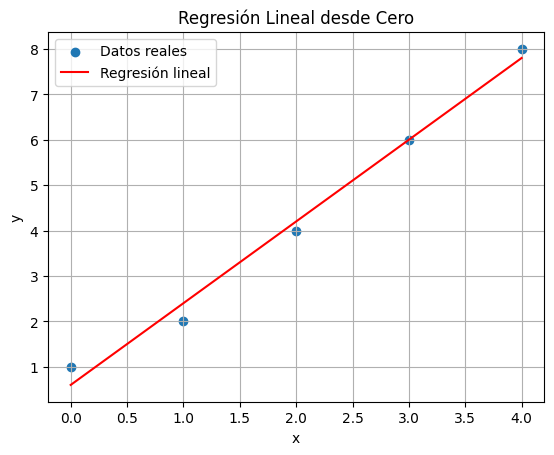

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([0, 1, 2, 3, 4])
y = np.array([1, 2, 4, 6, 8])

# Entrenamiento
b0, b1 = linear_regression(x, y)
print(f"Modelo: y = {b0:.2f} + {b1:.2f}x")

# Visualización
y_pred = predict(x, b0, b1)
plt.scatter(x, y, label="Datos reales")
plt.plot(x, y_pred, color="red", label="Regresión lineal")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.title("Regresión Lineal desde Cero")
plt.show()


### Clase

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

class SimpleLinearRegressor:
    def __init__(self):
        self.coef_ = None      # pendiente
        self.intercept_ = None # intercepto
        self.fitted = False
        self.lines = []

    def fit(self, x, y):
        """Ajusta la recta de regresión a los datos (mínimos cuadrados)"""
        x = np.array(x)
        y = np.array(y)
        self.x_ = x
        self.y_ = y

        x_mean = np.mean(x)
        y_mean = np.mean(y)

        # Cálculo explícito de beta_1 y beta_0
        num = np.sum((x - x_mean) * (y - y_mean))
        den = np.sum((x - x_mean) ** 2)
        self.coef_ = num / den
        self.intercept_ = y_mean - self.coef_ * x_mean

        self.fitted = True

        # Guardar línea ajustada para graficar
        self.lines.append((self.coef_, self.intercept_, 'Línea ajustada'))

    def predict(self, x):
        """Hace predicciones usando la recta ajustada"""
        if not self.fitted:
            raise Exception("Debes llamar a .fit(x, y) antes de predecir.")
        x = np.array(x)
        return self.coef_ * x + self.intercept_ # type: ignore

    def add_line(self, slope, intercept, label=None):
        """Agrega manualmente una línea para comparar"""
        if label is None:
            label = f"y = {slope}x + {intercept}"
        self.lines.append((slope, intercept, label))

    def plot(self, title="Comparación de líneas rectas"):
        """Grafica los puntos, la recta ajustada y líneas adicionales"""
        if not hasattr(self, 'x_') or not hasattr(self, 'y_'):
            raise Exception("Primero debes ajustar el modelo con .fit()")

        x_line = np.linspace(min(self.x_), max(self.x_), 100)

        plt.figure(figsize=(8, 6))
        plt.scatter(self.x_, self.y_, label='Puntos de datos')

        for slope, intercept, label in self.lines:
            y_vals = slope * x_line + intercept
            plt.plot(x_line, y_vals, label=label)

        plt.xlabel('x')
        plt.ylabel('y')
        plt.title(title)
        plt.grid(True)
        plt.legend()
        plt.show()


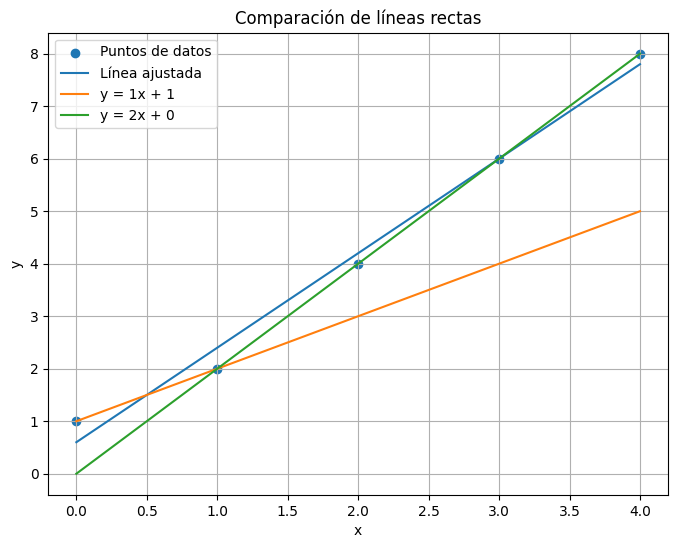

In [ ]:
# Datos
x = np.array([0, 1, 2, 3, 4])
y = np.array([1, 2, 4, 6, 8])

# Crear y ajustar modelo
model = SimpleLinearRegressor()
model.fit(x, y)

# Agregar líneas manuales (opcional)
model.add_line(1, 1, 'y = 1x + 1')
model.add_line(2, 0, 'y = 2x + 0')

# Predecir
x_pred = [1.5, 2.5]
y_pred = model.predict(x_pred)

# Graficar
model.plot()